# Navier–Stokes in two dimensions
## The lid-driven cavity: model, approximations, evidence

A single moving wall produces a primary circulation, thin wall layers and secondary corner vortices. This notebook connects that flow to an inspectable numerical method. It runs a small demonstration from scratch and displays the committed production evidence. **Large simulation caches are not required.**

[Read the illustrated report](../report/report.pdf) · [Reference provenance](../docs/references.md) · [Reproduction guide](../docs/reproducibility.md)

All velocities, lengths and times are dimensionless. The unit lid moves right.

In [1]:
from pathlib import Path
import os, sys, json, csv, tempfile
ROOT = Path.cwd() if (Path.cwd() / 'ns2d').is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / 'tmp/matplotlib'))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from ns2d import Grid, Cavity, Solver, __version__
from ns2d import postproc as pp, benchmark as bm, verification as vf, viz
print('ns2d', __version__, '| NumPy', np.__version__)

ns2d 1.3.0 | NumPy 2.5.2


### 1. Two scalar fields, one incompressible velocity

Define $u=\psi_y$, $v=-\psi_x$ and $\omega=v_x-u_y=-\Delta\psi$. Taking the curl eliminates pressure:

$$\omega_t+\psi_y\omega_x-\psi_x\omega_y=\mathrm{Re}^{-1}\Delta\omega,
\qquad-\Delta\psi=\omega.$$

The connected impermeable wall has $\psi=0$. The top wall moves with $(u,v)=(1,0)$ and the other walls are stationary. The upper corners are singular boundary junctions. We keep the discontinuous lid to match the classical benchmark.

The signs matter: a right-moving lid produces a clockwise primary circulation and a negative streamfunction minimum.

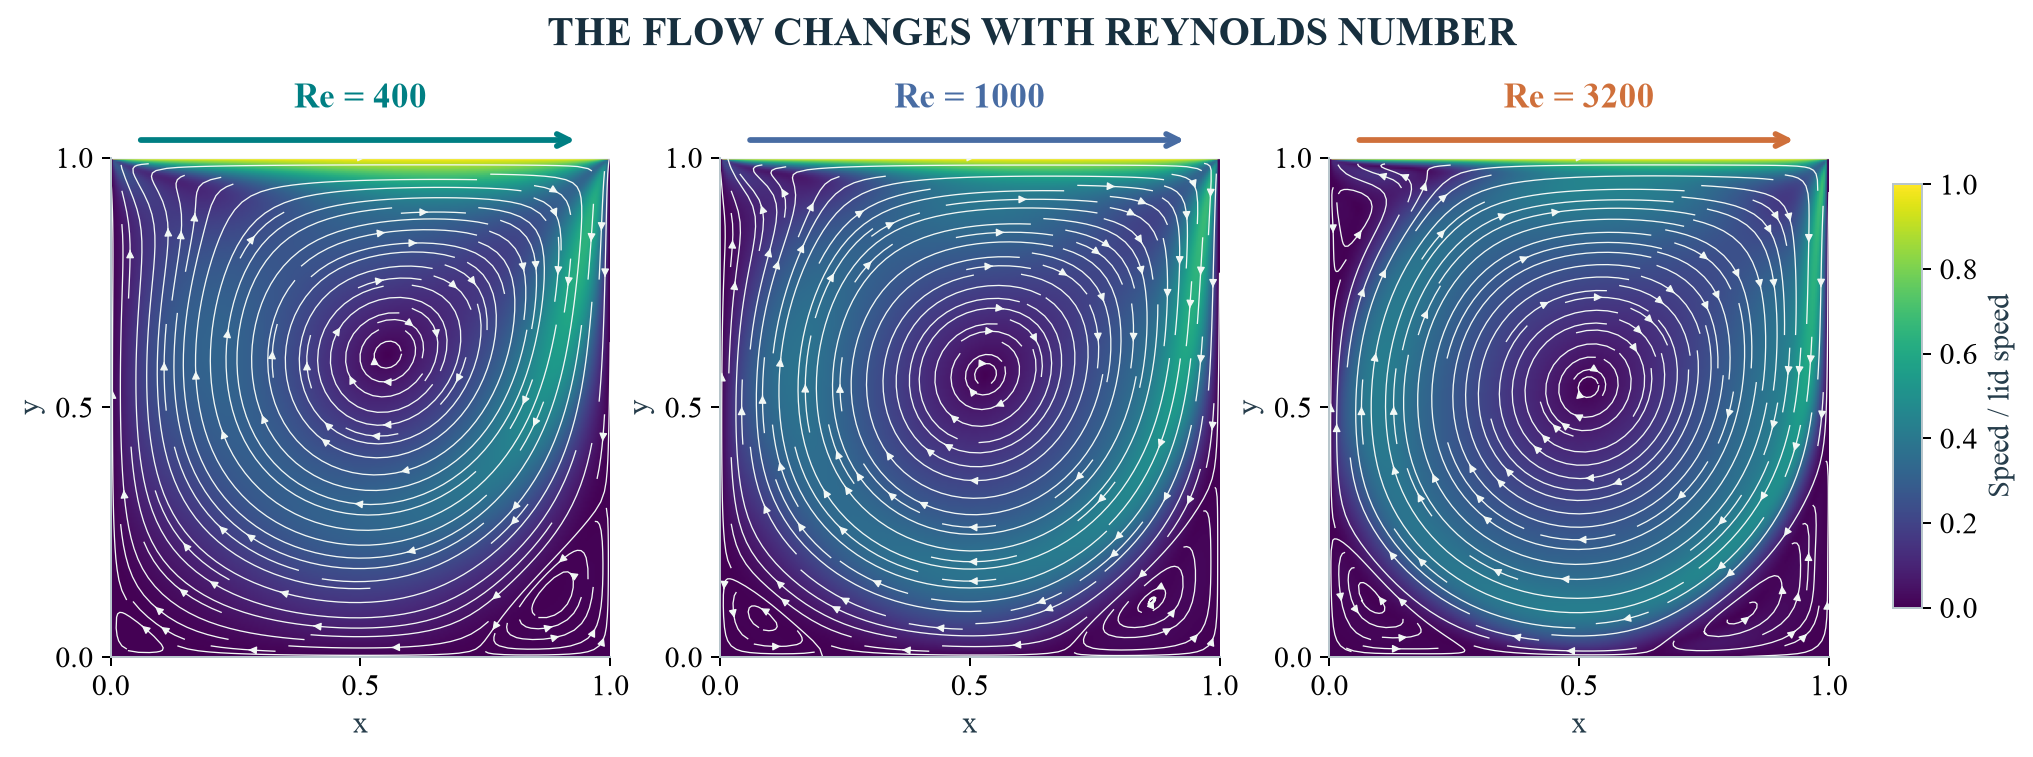

In [2]:
display(Image(filename=str(ROOT/'figures/flow_atlas.png'), width=1000))

### 2. Approximation choices

| Choice | Why it is useful | Limitation |
|---|---|---|
| Uniform finite differences | Short stencils and fast sine-transform solves | Thin wall layers require many points |
| Centered convection | Second-order consistency for smooth fields | No general monotonicity or energy-conservation guarantee |
| Explicit convection, implicit diffusion | Two fixed linear systems per step | First-order time accuracy; lagged walls still restrict the step |
| Thom wall vorticity | Transfers tangential no-slip to the scalar formulation | First-order local wall truncation error |

At the top wall, Taylor expansion gives
$$\omega_{i,N-1}=-2\psi_{i,N-2}/h^2-2U/h.$$

Writing $L=-\Delta_h$ on interior nodes and $b^n$ for the known wall ring, one step is
$$(I+\Delta t\,L/\mathrm{Re})\omega_I^{n+1}
=\omega_I^n-\Delta t\,C_h^n+(\Delta t/\mathrm{Re})(\Delta_hb^n)_I,$$
$$L\psi_I^{n+1}=\omega_I^{n+1}.$$
Both matrices are SPD. `backend='dst'` is the fast default; `lu` and IC(0)-preconditioned `cg` provide independent checks.

### 3. Run a small cavity from rest

This **65² demonstration** is the coarsest resolution used in the lower-Re grid study. The headline flow figures use 257² grids; compare both the grid and stopping condition when interpreting its output. `Solver` selects a conservative fixed step from the lid speed, Reynolds number and mesh. It is guidance rather than a nonlinear stability guarantee.

dt=0.0025, t=61.100, residual=9.877e-07
Steady criterion met: True; primary vortex: (-0.10905189413166007, 0.5583256246173958, 0.6102049221162713)


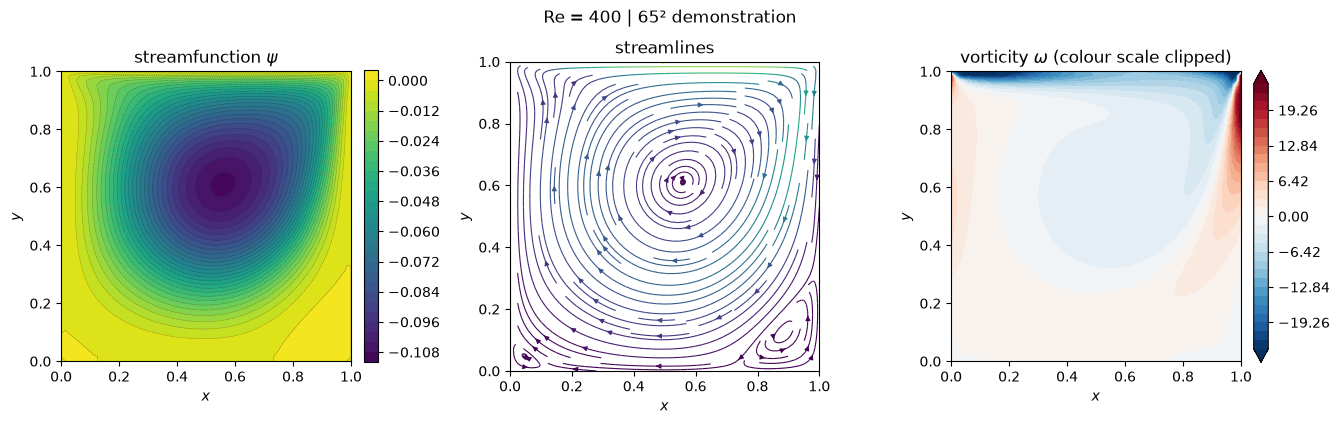

In [3]:
grid = Grid.square(65)
solver = Solver(grid, Cavity(Re=400))
result = solver.run(T=80., steady_tol=1e-6, progress=False, record=False)
vortex = pp.primary_vortex(solver.psi, grid)
print(f'dt={solver.dt:.6g}, t={result.t_final:.3f}, residual={result.final_residual:.3e}')
print(f'Steady criterion met: {result.converged}; primary vortex: {vortex.as_tuple()}')
fig, _ = viz.plot_solution(solver.psi, solver.omega, grid, suptitle='Re = 400 | 65² demonstration')
plt.show()

In [4]:
u, v = solver.velocity()
print(bm.compare_to_ghia(u, v, grid, 400).summary())
print(f'Poisson residual: {pp.poisson_residual(solver.psi, solver.omega, grid):.3e}')
print(f'Max discrete divergence: {pp.max_divergence(u, v, grid):.3e}')
print(f'Stored circulation (lagged wall): {pp.total_circulation(solver.omega, grid):.12f}')
print(f'Consistent circulation identity: {pp.circulation_identity(solver.psi, grid, Cavity(400).walls(grid, solver.t)):.12f}')

Ghia et al. (1982), Re=400 (all 17 u / 17 v stations)
  u RMS = 1.252e-02, max = 2.376e-02
  v RMS = 3.254e-02, max = 1.219e-01
  without flagged v stations [0.9063]: RMS = 1.399e-02
Poisson residual: 9.690e-13
Max discrete divergence: 3.553e-15
Stored circulation (lagged wall): -1.000000000015
Consistent circulation identity: -1.000000000000


### 4. Measure accuracy with a known solution

For
$$\psi_e=\sin(\pi x)\sin(\pi y)e^{-t}+\tfrac12\sin(2\pi x)\sin(2\pi y)e^{-2t},$$
we set $\omega_e=-\Delta\psi_e$ and derive the continuous forcing symbolically. Both wall motion and nonlinear convection are nonzero. The following small refinement study uses the production Thom boundary path; it runs without any saved data.

In [5]:
study = vf.spatial_convergence(sizes=(17,33,65), dt=1e-5, T=.005, omega_bc='thom', verbose=False)
print(study.table())

Spatial convergence  (omega BC: thom, Re=100, dt=1e-05 fixed, T=0.005)
---------------------------------------------------------------------------------------
    N          h         dt       psi_l2      p     omega_l2      p    omega_inf      p
---------------------------------------------------------------------------------------
   17  6.250e-02  1.000e-05   3.6422e-03     --   3.2609e-01     --   1.5626e+00     --
   33  3.125e-02  1.000e-05   9.1113e-04   2.00   1.0773e-01   1.60   7.3908e-01   1.08
   65  1.562e-02  1.000e-05   2.2955e-04   1.99   3.0537e-02   1.82   2.9022e-01   1.35
---------------------------------------------------------------------------------------


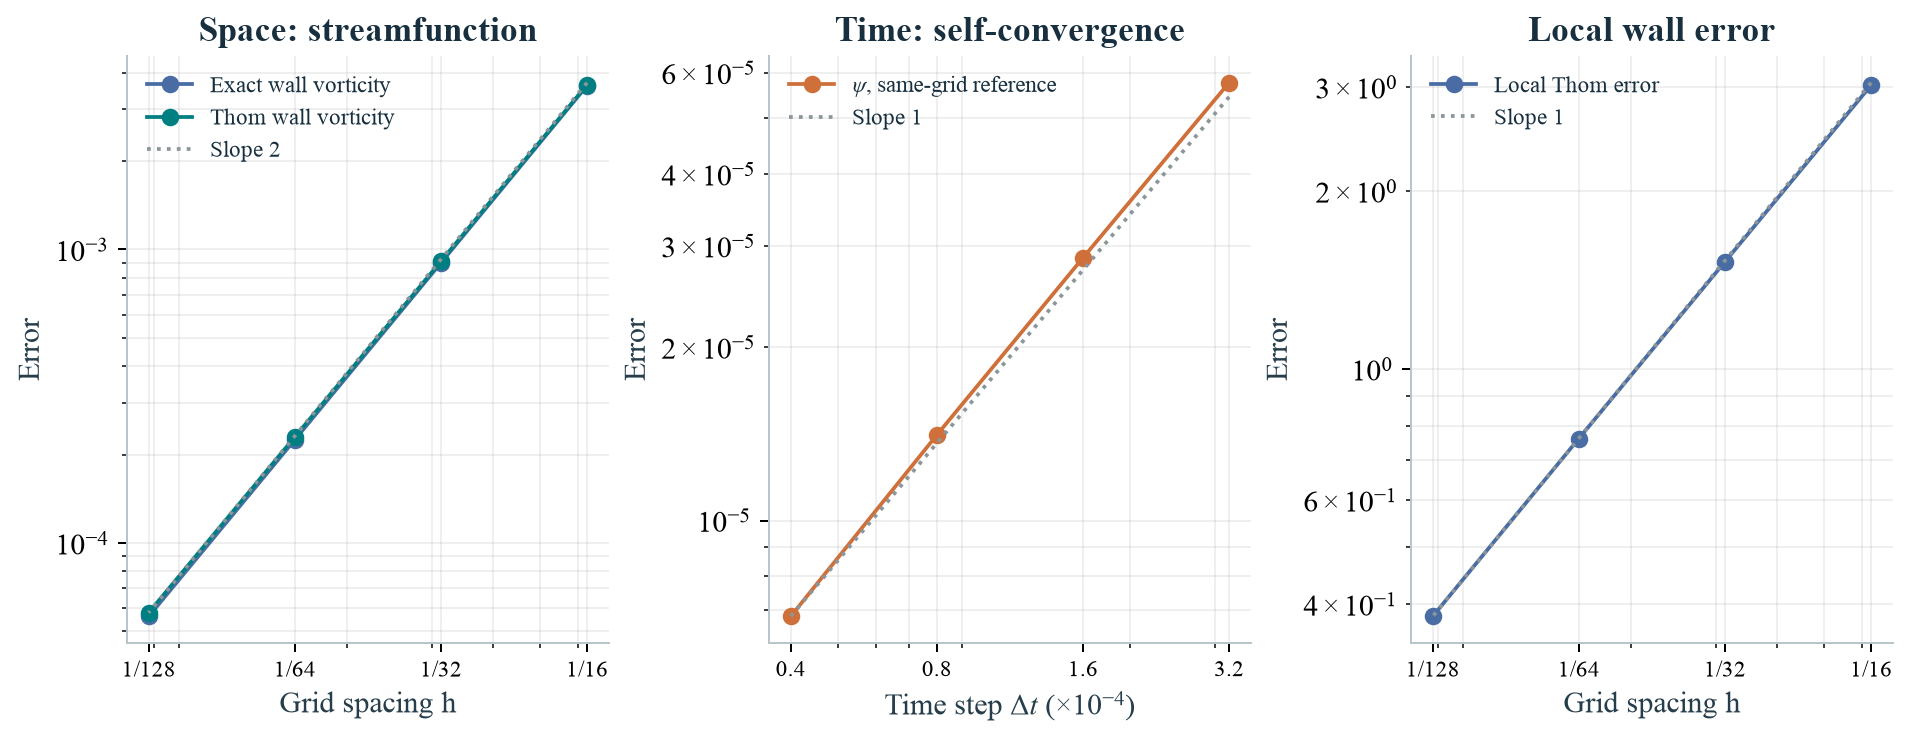

In [6]:
display(Image(filename=str(ROOT/'figures/verification.png'), width=1000))

The figure shows the fuller committed experiment. Streamfunction error is approximately second order in space, temporal self-convergence approximately first order, and the local Thom truncation error approximately first order. Vorticity orders vary with mesh and norm; consult `data/verification.json` for the complete sequence. The four inert vorticity corners are excluded from both vorticity norms.

A same-grid fine-time-step reference reduces the spatial error floor in a temporal study; it is still a numerical reference, so the measured order is slightly biased.

### 5. Inspect the production evidence

All nine states were integrated afresh from rest with the recorded solver source. The results builder validates the run provenance and file hashes, checks the equations and a continuation step, and recomputes all benchmark metrics. The following table and plots are committed, so a fresh clone can display them without the large field caches.

| Re | Grid | Final time | Residual | Steady? | ψ minimum | Ghia difference |
|---:|---:|---:|---:|:---:|---:|---:|
| 400 | 65² | 61.12 | 9.80e-07 | yes | -0.109052 | 4.26% |
| 400 | 129² | 61.37 | 9.68e-07 | yes | -0.112776 | 0.99% |
| 400 | 257² | 61.62 | 9.88e-07 | yes | -0.113689 | 0.19% |
| 1000 | 65² | 140.00 | 9.97e-07 | yes | -0.105252 | 10.75% |
| 1000 | 129² | 149.70 | 9.98e-07 | yes | -0.115473 | 2.08% |
| 1000 | 257² | 156.40 | 9.97e-07 | yes | -0.118074 | 0.12% |
| 3200 | 129² | 510.66 | 1.00e-06 | yes | -0.109979 | 8.64% |
| 3200 | 193² | 534.75 | 1.00e-06 | yes | -0.116413 | 3.29% |
| 3200 | 257² | 543.11 | 1.00e-06 | yes | -0.118734 | 1.37% |


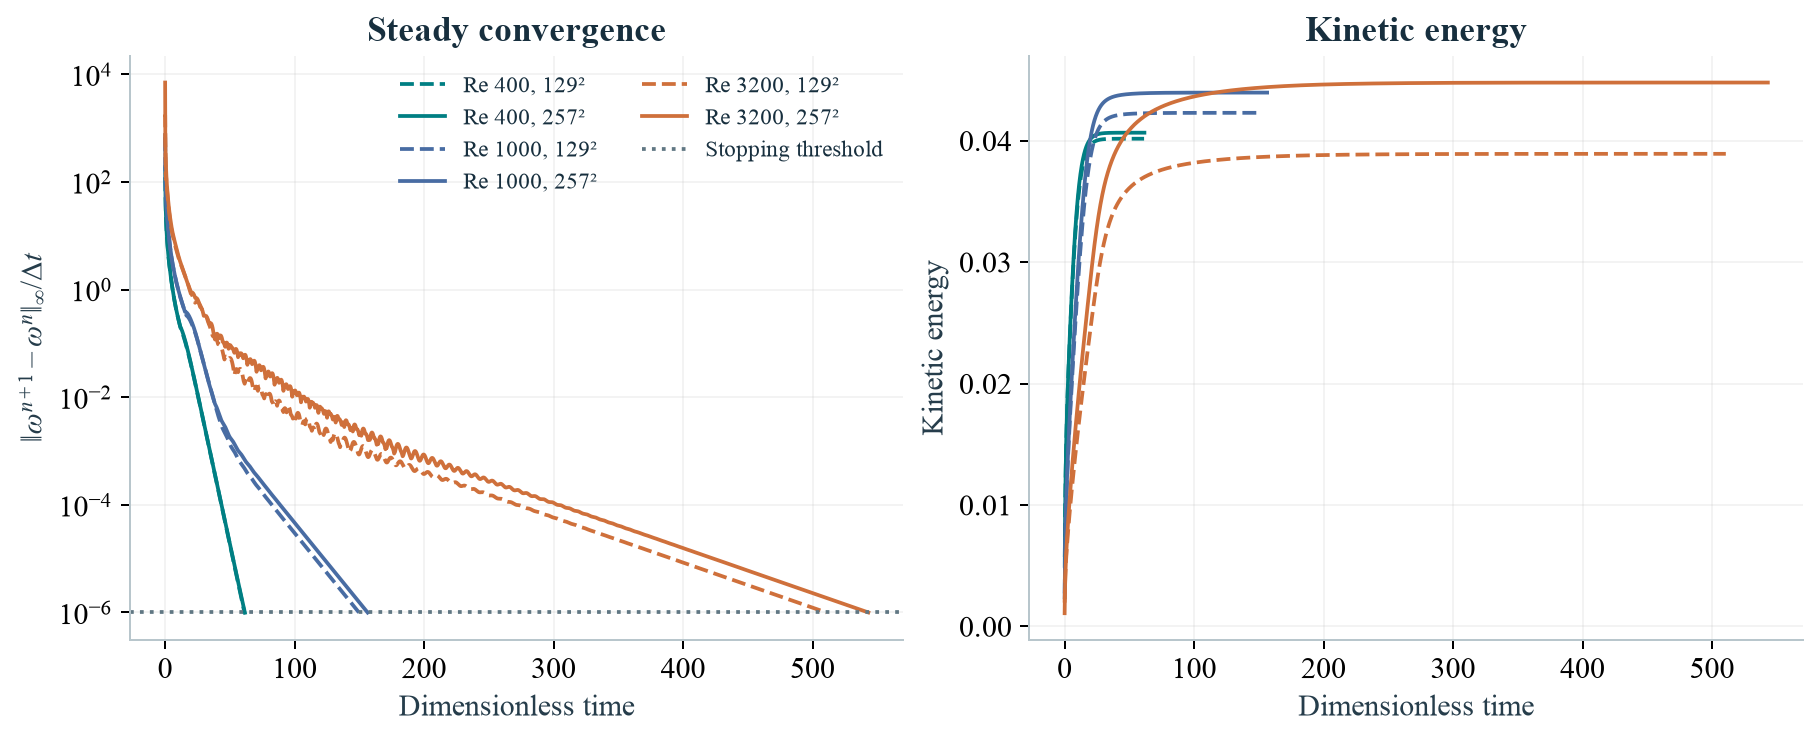

In [7]:
display(Markdown((ROOT/'data/results_table.md').read_text()))
display(Image(filename=str(ROOT/'figures/residuals.png'), width=1000))

All nine production states meet the same $10^{-6}$ residual threshold. Each is then continued for ten more time units with both dt and dt/2 to measure settling sensitivity. The steady PDE defect is evaluated separately from the filtered update rate.

Three grids per Reynolds number support conditional Richardson estimates. Their power-law assumption is stated explicitly, and non-monotone observables retain an unavailable order rather than a forced fit. An independent 513² run at Re = 400 tests the primary-streamfunction extrapolation; `data/fourth_grid.json` retains its prediction error and the change between overlapping three-grid fits.

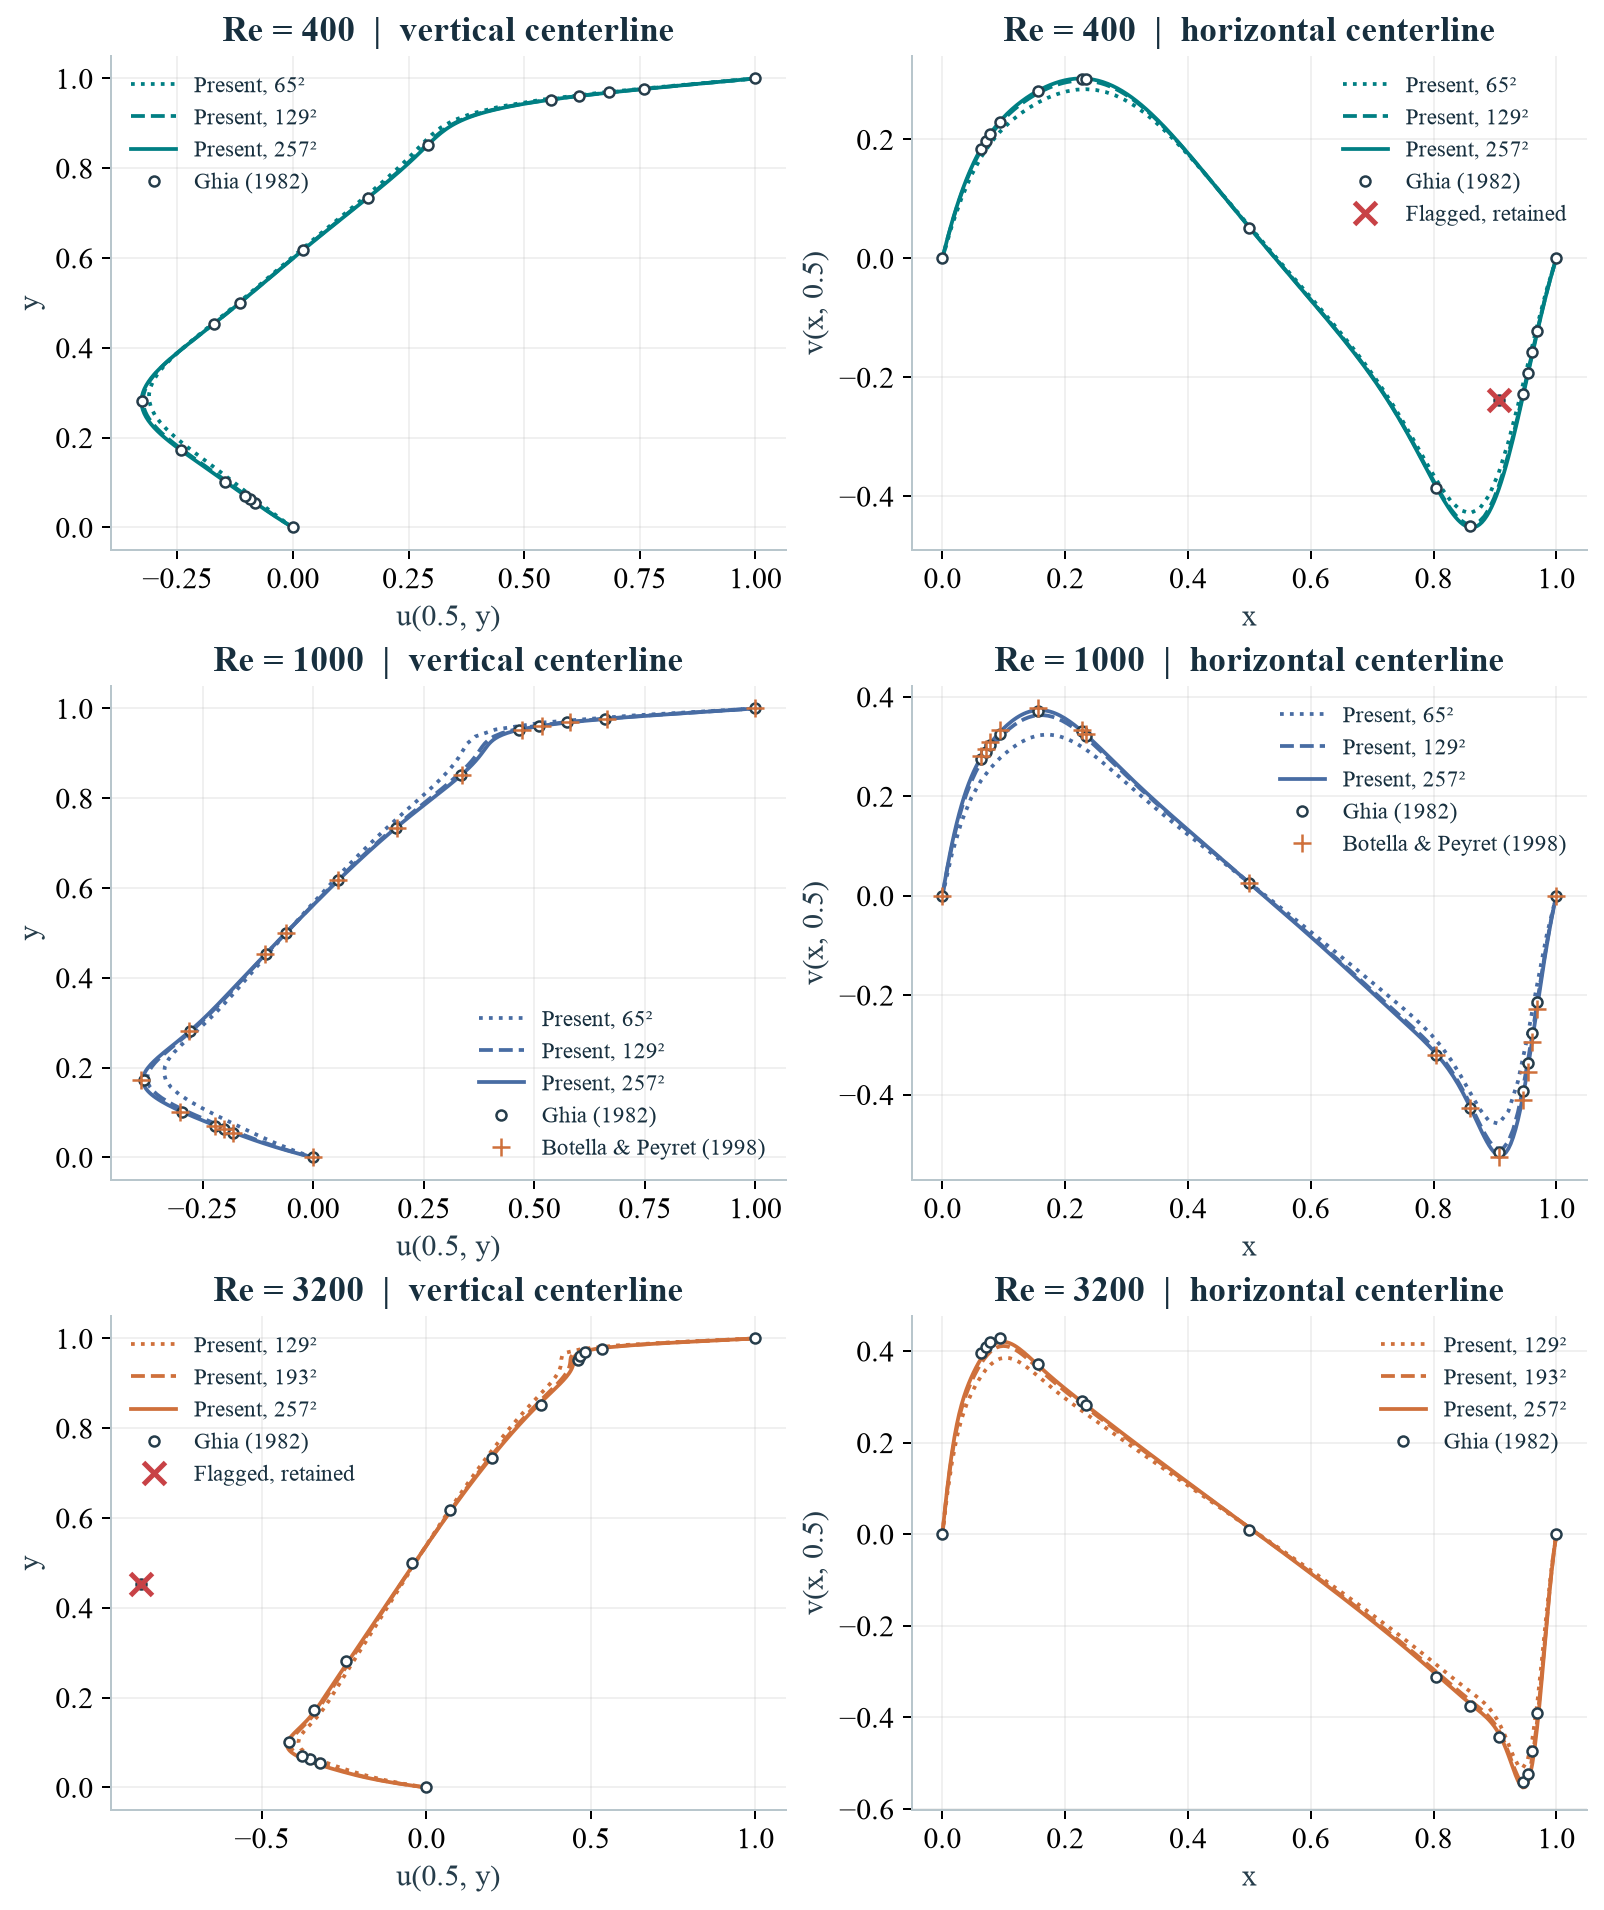

In [8]:
display(Image(filename=str(ROOT/'figures/centerlines.png'), width=850))

### 6. Compare references without changing them to fit

Ghia's printed $u=-0.86636$ at Re = 3200, $y=0.4531$, and $v=-0.23827$ at Re = 400, $x=0.9063$, are retained in the headline RMS. Secondary scores omit these explicitly flagged stations. They are diagnostic comparisons, not corrected source data. A local transcription was fixed to match the paper: at Re = 1000, $x=0.9063$, $v=-0.51550$.

Botella & Peyret provide an independent spectral reference at Re = 1000. Their lid moves left, requiring the reflection $x_R=1-x_L$, $u_R=-u_L$, $v_R=v_L$, $\psi_R=-\psi_L$. In particular, the vertical velocity does **not** change sign.

In [9]:
rows = json.loads((ROOT/'data/validation.json').read_text())
r = next(row for row in rows if row['Re']==1000 and row['N']==257)
print(f"Present primary psi: {r['psi_min']:.7f}")
print(f"Ghia discrepancy: {r['psi_error_percent']:.3f}%")
print(f"Botella–Peyret discrepancy: {r['botella_psi_error_percent']:.3f}%")
print(f"u RMS: Ghia {r['u_rms']:.3e}, Botella–Peyret {r['botella_u_rms']:.3e}")
print(f"v RMS: Ghia {r['v_rms']:.3e}, Botella–Peyret {r['botella_v_rms']:.3e}")

Present primary psi: -0.1180744
Ghia discrepancy: 0.123%
Botella–Peyret discrepancy: 0.725%
u RMS: Ghia 1.806e-03, Botella–Peyret 2.724e-03
v RMS: Ghia 6.614e-03, Botella–Peyret 3.113e-03


### 7. Separate grid sensitivity, transient accuracy and settling

The three-grid estimate for each scalar output assumes $q(h)=q_0+Ch^p$. Actual grid ratios are used, including 129²/193²/257² at Re = 3200. This is a conditional estimate, not a rigorous bound or proof that all grids are asymptotic. Profiles are compared at 65 common uniform grid stations, separately from the literature RMS.

Time accuracy is tested with fresh runs to the same transient time T = 5 at N = 129, using dt, dt/2 and dt/4. At an exactly steady discrete state, dt cancels from the fixed-point equations. The final-state step-halving experiment therefore measures settling sensitivity rather than steady time-truncation error.

| Re | Three-grid fitted order | Conditional GCI for ψ minimum | Ten-time-unit ψ drift |
|---:|---:|---:|---:|
| 400 | 2.027 | 0.327% | 1.830e-05% |
| 1000 | 1.974 | 0.941% | 7.603e-05% |
| 3200 | 1.917 | 3.321% | 7.843e-05% |

GCI is a conditional power-law estimate, not a rigorous bound. Settling drift is the larger change during two independent ten-time-unit continuations with dt and dt/2; it is not an infinite-time error bound.


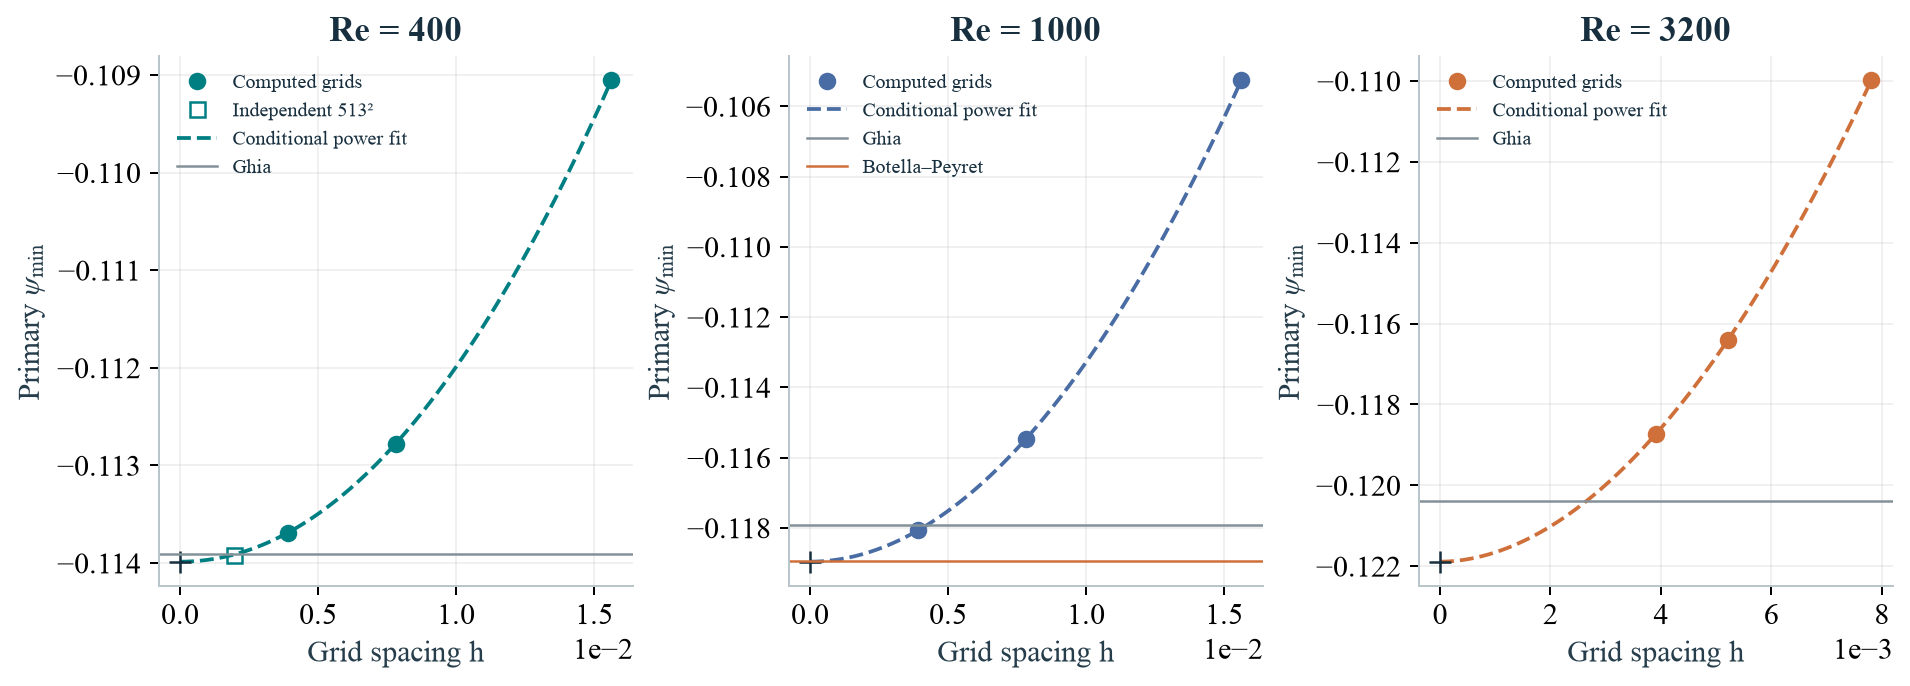

In [10]:
display(Markdown((ROOT/'data/accuracy_summary.md').read_text()))
display(Image(filename=str(ROOT/'figures/grid_convergence.png'), width=1000))

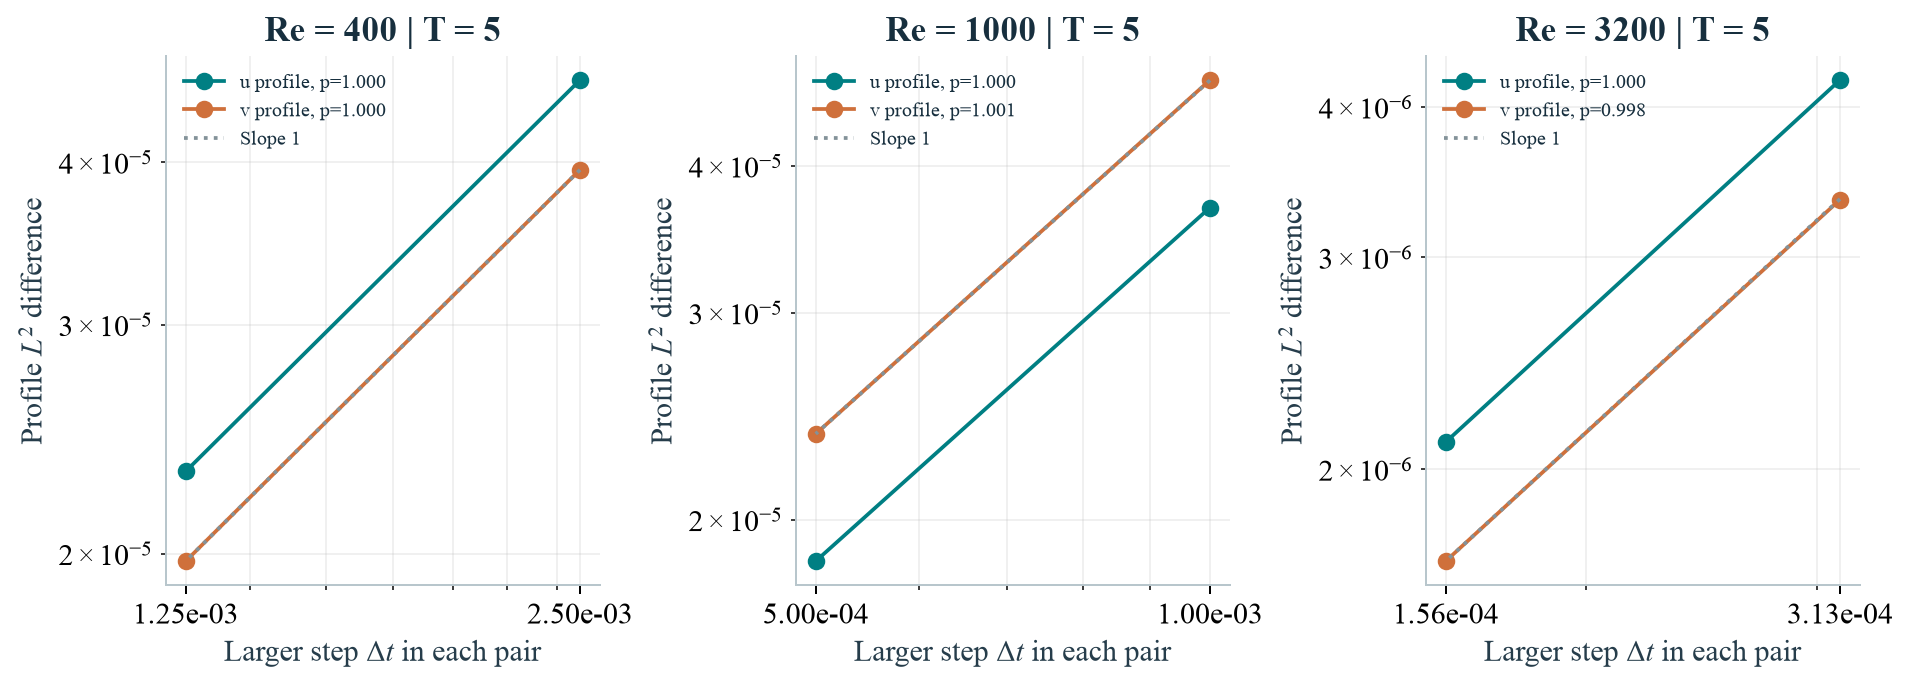

In [11]:
display(Image(filename=str(ROOT/'figures/cavity_time_convergence.png'), width=1000))

In [12]:
accuracy = json.loads((ROOT/'data/accuracy.json').read_text())
for study in accuracy['temporal']:
    print('Re', study['Re'], '| transient profile orders:', study['profile_orders'])
for study in accuracy['steady']:
    if study['N'] == 257:
        drift = max(trial['drift']['psi_min_change_percent'] for trial in study['trials'])
        print('Re', study['Re'], '| ten-unit primary-vortex drift (%):', drift)

Re 400 | transient profile orders: {'u_l2': 0.9999593455475095, 'v_l2': 1.0001927593340174}
Re 1000 | transient profile orders: {'u_l2': 0.999992896125303, 'v_l2': 1.0006342052948805}
Re 3200 | transient profile orders: {'u_l2': 0.9996584009844754, 'v_l2': 0.9981239744325524}
Re 400 | ten-unit primary-vortex drift (%): 1.8301525544661907e-05
Re 1000 | ten-unit primary-vortex drift (%): 7.603153387032791e-05
Re 3200 | ten-unit primary-vortex drift (%): 7.843176159936614e-05


### 8. Restart a calculation safely

A checkpoint records the numerical configuration as well as the fields. Strict loading rejects incompatible time steps, domains, boundary modes and built-in problem parameters. `strict=False` is an explicit state import, not a claim of identical continuation.

In [13]:
g = Grid.square(17)
a = Solver(g, Cavity(400), dt=.001)
a.run(n_steps=10, progress=False, record=False)
with tempfile.TemporaryDirectory() as folder:
    checkpoint = Path(folder)/'state.npz'
    a.save(checkpoint)
    b = Solver(g, Cavity(400), dt=.001)
    b.load(checkpoint)
    a.run(n_steps=10, progress=False, record=False)
    b.run(n_steps=10, progress=False, record=False)
    print('Identical DST continuation:', np.array_equal(a.psi,b.psi) and np.array_equal(a.omega,b.omega))

Identical DST continuation: True


### Explore further

Change the demo's Reynolds number, grid or backend and compare both the flow and its residual. For a resolution study, keep the physical problem and stopping tolerance fixed. For a time study, keep the grid fixed and compare at the same physical time.

Rebuild the full evidence from the repository root:
```bash
python scripts/run_production.py --force
python scripts/check_fourth_grid.py
python scripts/run_accuracy.py
python scripts/build_results.py
```

The [report](../report/report.pdf) derives the equations and explains the limitations. The [reference notes](../docs/references.md) identify exact tables, flags and coordinate conventions.

Sources: [Ghia et al. (1982)](https://doi.org/10.1016/0021-9991(82)90058-4), [Botella & Peyret (1998)](https://doi.org/10.1016/S0045-7930(98)00002-4).